# Four-metric scientific interaction suite

Selected settings: off/155/001/003/046. Offline extraction from saved original Astra traces and native evaluations only. No new LLM calls, embeddings, annotations, or scientific runs. [Report](REPORT.md) · [Candidate caption and handoff](FIGURE_CAPTION.md) · [Plan](PLAN.md). Existing semantic, behavior, performance and recovery figures remain unchanged.

In [1]:
from pathlib import Path
import sys,json,csv,subprocess
from IPython.display import display,Markdown,Image,Code
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/09_offline_metric_suite/code'))
import extract,analyze,report,plot
BASE=extract.BASE
REEXTRACT=False  # Reads frozen local files only.
RECOMPUTE=False  # Uses the saved extraction; no inference.
if REEXTRACT or not (extract.DATA/'snapshot.json').exists(): extract.main()
if RECOMPUTE or not (extract.DATA/'summary.json').exists(): analyze.main()
snap=json.loads((extract.DATA/'snapshot.json').read_text())
s=json.loads((extract.DATA/'summary.json').read_text())
report.main()
print(json.dumps({'policy':snap['policy'],'input_hashes':snap['provenance'],'bootstrap':s['bootstrap']},indent=2))

Report, caption, and status written.


{
  "policy": "Original endpoints only; no new LLM inference; existing native judgments reused.",
  "input_hashes": [
    {
      "path": "Experiment/01_behavioral_diversity/data/behavior_all_personas/snapshot.json",
      "sha256": "37e6d1029ed7690347d94c62d66e728e82e4f552794005c6e78946f740276e00"
    },
    {
      "path": "Experiment/02_performance_and_fields/data/all_available/snapshot.json",
      "sha256": "32653a253228c0a71f10f7b691c985fd7d9e36aadcc05880bce5769e6ce3569f"
    },
    {
      "path": "runs/repair-1-openai-astra-top10-trial-1-batch-2/original_results_snapshot.json",
      "sha256": "aae45594d7123c9c3a347003a0f772f97c61d6eea78679f04f7d605413d6af3d"
    },
    {
      "path": "runs/repair-1-openai-astra-top10-trial-2-batch-2/original_results_snapshot.json",
      "sha256": "4c5eb6c5ed5a49c198c0c178e0743b262ac6c23a9f3e4b5a8a49a42e6d9af01a"
    },
    {
      "path": "runs/repair-1-openai-astra-top10-trial-3-batch-2/original_results_snapshot.json",
      "sha256": "6337

## Coverage and matching
All metrics use original endpoints. Trace repetition uses a common panel with ≥2 complete traces for off/155/001 and ≥1 for 003/046; no invented within-persona repetitions for single-trial settings. Native outcome panels use all eligible original scores. Fact recovery uses only disambiguation; binary failure coverage uses only Bix correctness and SciConv FRR. Populations differ across panels and are explicitly reported.

In [2]:
from collections import Counter
print('Original slots:',len(snap['scores']))
print('Complete traces:',sum(r.get('exclusion') is None for r in snap['traces']))
print('Saved recovery judgements:',sum(r['recovery'] is not None for r in snap['recovery']))
print('Repetition panel:',dict(Counter(r['source'] for r in s['repetition_coverage'])))
print('Failure panel:',dict(Counter(r['source'] for r in s['failure_panel'])))
display(Markdown(report.table(['Source','Off','155','001','003','046'],[[source,*[sum(r.get('exclusion') is None and r['source']==source and r['arm']==a for r in snap['traces']) for a in extract.ARMS]] for source in extract.SOURCES])))

Original slots: 2200
Complete traces: 1958
Saved recovery judgements: 220
Repetition panel: {'asibench': 7, 'bixbench': 27, 'discoverybench': 21, 'expbench': 5, 'sciconvbench': 40}
Failure panel: {'bixbench': 26, 'sciconvbench': 40}


| Source | Off | 155 | 001 | 003 | 046 |
|---|---|---|---|---|---|
| asibench | 93 | 96 | 109 | 8 | 23 |
| bixbench | 117 | 117 | 119 | 28 | 37 |
| discoverybench | 115 | 107 | 115 | 22 | 37 |
| expbench | 120 | 105 | 105 | 6 | 39 |
| sciconvbench | 120 | 120 | 120 | 40 | 40 |

## Estimators
**Repetition:** for each question, fraction of identical canonical event sequences across persona-rollout pairs; within-persona cells use distinct repeats only. Equal question weights within benchmark and equal benchmark weights in the aggregate. Lower repetition describes more structural variation, not better science. **Recovery:** saved recovered/total deleted-fact counts, averaged within case across observed trials. **Native scores:** retain each source’s native scale; paired contrasts require matching task/trial and compatible evaluators. **Failure coverage:** enumerate size-m off-trial subsets versus size-m distinct-persona subsets, choosing each persona’s available trial uniformly. At m=1,2,3, estimate expected fraction of questions with ≥1 native scientific failure. No best-performing/worst-performing persona subset is chosen. Study-cluster bootstrap CIs condition on the observed trials. No new significance tests.

In [3]:
display(Markdown(report.table(['Setting','Fact recovery [95% CI]','Matched change from off'],[[label,report.cell(report.pick(s['outcomes'],metric='fact_recovery',arm=a,level='all',group='all')),'Reference' if a==extract.ARMS[0] else report.cell(report.pick(s['contrasts'],metric='fact_recovery',persona_i=a,persona_j=extract.ARMS[0],level='all',group='all'))] for a,label in zip(extract.ARMS,extract.LABELS)])))
display(Markdown(report.table(['Benchmark','Budget','Off','Mixture','Matched difference'],[[report.NAMES[source],m,*[report.cell(report.pick(s['failure_coverage'],variant='primary',level='source',group=source,budget=m,strategy=strategy)) for strategy in ['off','mixture','difference']]] for source in ['bixbench','sciconvbench'] for m in [1,2,3]])))
print('Aggregate repetition:',json.dumps(s['repetition_overview'],indent=2))

| Setting | Fact recovery [95% CI] | Matched change from off |
|---|---|---|
| Off | 84.70 [70.42, 96.37]; n=20, g=20 | Reference |
| 155 | 88.63 [75.30, 99.88]; n=20, g=20 | 3.93 [-0.24, 11.31]; n=20, g=20 |
| 001 | 88.69 [75.71, 99.52]; n=20, g=20 | 3.99 [0.00, 11.07]; n=20, g=20 |
| 003 | 91.70 [80.00, 99.29]; n=20, g=20 | 5.54 [-1.43, 16.79]; n=20, g=20 |
| 046 | 86.43 [71.43, 98.57]; n=20, g=20 | 0.27 [-1.07, 1.88]; n=20, g=20 |

| Benchmark | Budget | Off | Mixture | Matched difference |
|---|---|---|---|---|
| BixBench | 1 | 61.54 [36.36, 88.00]; n=26, g=20 | 61.54 [36.36, 88.00]; n=26, g=20 | 0.00 [0.00, 0.00]; n=26, g=20 |
| BixBench | 2 | 61.54 [36.36, 88.00]; n=26, g=20 | 61.54 [36.36, 88.00]; n=26, g=20 | 0.00 [0.00, 0.00]; n=26, g=20 |
| BixBench | 3 | 61.54 [36.36, 88.00]; n=26, g=20 | 61.54 [36.36, 88.00]; n=26, g=20 | 0.00 [0.00, 0.00]; n=26, g=20 |
| SciConvBench | 1 | 15.00 [5.83, 25.00]; n=40, g=40 | 16.25 [8.54, 25.21]; n=40, g=40 | 1.25 [-5.83, 8.33]; n=40, g=40 |
| SciConvBench | 2 | 19.17 [7.50, 31.67]; n=40, g=40 | 23.94 [13.89, 35.05]; n=40, g=40 | 4.77 [-5.42, 15.28]; n=40, g=40 |
| SciConvBench | 3 | 20.00 [7.50, 32.50]; n=40, g=40 | 29.44 [17.57, 42.01]; n=40, g=40 | 9.44 [-1.32, 21.25]; n=40, g=40 |

Aggregate repetition: {
  "between_all_pairs": {
    "mean": 83.5627572016461,
    "ci95": [
      79.13709529645192,
      87.65191888547533
    ],
    "tasks": 100,
    "episodes": 1000,
    "studies": 77,
    "source_counts": {
      "asibench": 7,
      "bixbench": 27,
      "discoverybench": 21,
      "expbench": 5,
      "sciconvbench": 40
    },
    "studies_by_source": {
      "asibench": 7,
      "bixbench": 20,
      "discoverybench": 5,
      "expbench": 5,
      "sciconvbench": 40
    },
    "singleton_sources": []
  },
  "between_minus_within_off": {
    "mean": -1.6162551440329231,
    "ci95": [
      -5.135796904335213,
      2.187770655270636
    ],
    "tasks": 100,
    "episodes": 1000,
    "studies": 77,
    "source_counts": {
      "asibench": 7,
      "bixbench": 27,
      "discoverybench": 21,
      "expbench": 5,
      "sciconvbench": 40
    },
    "studies_by_source": {
      "asibench": 7,
      "bixbench": 20,
      "discoverybench": 5,
      "expbench": 5,
  

## Rendered figures
Main and supporting figures use the established semantic-figure typography and persona palette. Diagonal repetition cells describe within-persona repeats, not distance zeroes; dashes mean unavailable. The main native-score heatmap gives estimates, with full CIs in the supporting figure and report. All source data are retained. Shaded coverage bands are pointwise 95% CIs, not variation across independently regenerated campaigns.

"""Paper-ready four-metric figures, matching the established semantic-figure palette."""
import sys,json,csv
from collections import defaultdict
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from extract import ROOT,BASE,DATA,ARMS,SOURCES,FAMILIES,LABELS,write_csv
sys.path.insert(0,str(ROOT/'Experiment/01_behavioral_diversity/code'))
from audit_panel_alignment import require_matplotlib_panel_alignment
FIG=BASE/'figures';COLORS=['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']
NAMES=dict(zip(SOURCES,['ASI-Bench','BixBench','DiscoveryBench','EXP-Bench','SciConvBench']))
NAMES.update(dict(zip(FAMILIES,['Life sciences','Physical / engineering','Math / CS','Social / humanities'])))
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':7,'axes.labelsize':7,'axes.titlesize':8,'xtick.labelsize':6,'ytick.labelsize':6,'svg.fonttype':'none','pdf.fonttype':42,'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.6})

def pick(rows,**kw):
 match=[r for r in rows if all(r.get(k)==v for k,v in kw.items())]
 assert len(match)==1,(kw,len(match))
 return match[0]

def axes_clean(ax):
 for spine in ax.spines.values():spine.set_visible(False)
 ax.tick_params(length=0,pad=4)

def repetition_heat(ax,s,level='all',group='all',variant='primary'):
 matrix=np.full((5,5),np.nan)
 for i,a in enumerate(ARMS):
  for j,b in enumerate(ARMS[:i+1]):
   r=pick(s['repetition'],persona_i=a,persona_j=b,level=level,group=group,variant=variant)
   if r['mean'] is not None:matrix[i,j]=r['mean']
 cmap=plt.get_cmap('PuBuGn').copy();cmap.set_bad('white');im=ax.imshow(matrix,cmap=cmap,vmin=0,vmax=100,aspect='auto')
 for i in range(5):
  for j in range(i+1):
   m=matrix[i,j]
   if np.isnan(m):ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='#EEEEEE',edgecolor='none'));txt='—';color='#777777'
   else:txt=f'{m:.1f}';color='white' if m>65 else '#182229'
   ax.text(j,i,txt,ha='center',va='center',fontsize=7,color=color)
 ax.set_xticks(range(5),LABELS);ax.set_yticks(range(5),LABELS);axes_clean(ax)
 return im

def score_heat(ax,s,field,groups,show_ci=False):
 matrix=np.array([[pick(s['outcomes'],metric='native_score',arm=a,level=field,group=g)['mean'] for g in groups] for a in ARMS],float)
 cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#EEEEEE');im=ax.imshow(matrix,cmap=cmap,vmin=0,vmax=100,aspect='auto')
 for i,a in enumerate(ARMS):
  for j,g in enumerate(groups):
   r=pick(s['outcomes'],metric='native_score',arm=a,level=field,group=g);m=r['mean'];ci=r['ci95']
   txt='—' if m is None else f'{m:.1f}'
   if show_ci:txt+='\n'+(f'[{ci[0]:.1f}, {ci[1]:.1f}]' if ci else 'CI unavailable')
   ax.text(j,i,txt,ha='center',va='center',fontsize=6.5 if show_ci else 7,color='white' if m is not None and m>65 else '#182229',linespacing=1.4)
 labels=[NAMES[g].replace('DiscoveryBench','Discovery\nBench').replace('SciConvBench','SciConv\nBench').replace('Physical / engineering','Physical /\nengineering').replace('Social / humanities','Social /\nhumanities')+('*' if g=='asibench' else '') for g in groups]
 ax.set_xticks(range(len(groups)),labels);ax.set_yticks(range(5),LABELS);axes_clean(ax)
 return im

def save(fig,name,groups,exclude=()):
 fig.canvas.draw()
 for k,axes in enumerate(groups):
  ids=[f'p{i}' for i in range(len(axes))];rows=defaultdict(list);cols=defaultdict(list)
  for ident,axis in zip(ids,axes):
   pos=axis.get_position();rows[(round(pos.y0,6),round(pos.y1,6))].append(ident);cols[(round(pos.x0,6),round(pos.x1,6))].append(ident)
  require_matplotlib_panel_alignment(fig,panel_ids=ids,row_groups=[v for v in rows.values() if len(v)>1],column_groups=[v for v in cols.values() if len(v)>1],json_out=str(FIG/f'qa/{name}.alignment{k}.json'),overlay_svg=str(FIG/f'qa/{name}.alignment{k}.svg'),strict=True,tolerance_pt=1.5,axes=axes,exclude_axes=exclude)
 fig.savefig(FIG/(name+'.pdf'),f

Saved main figure and two supporting figures.


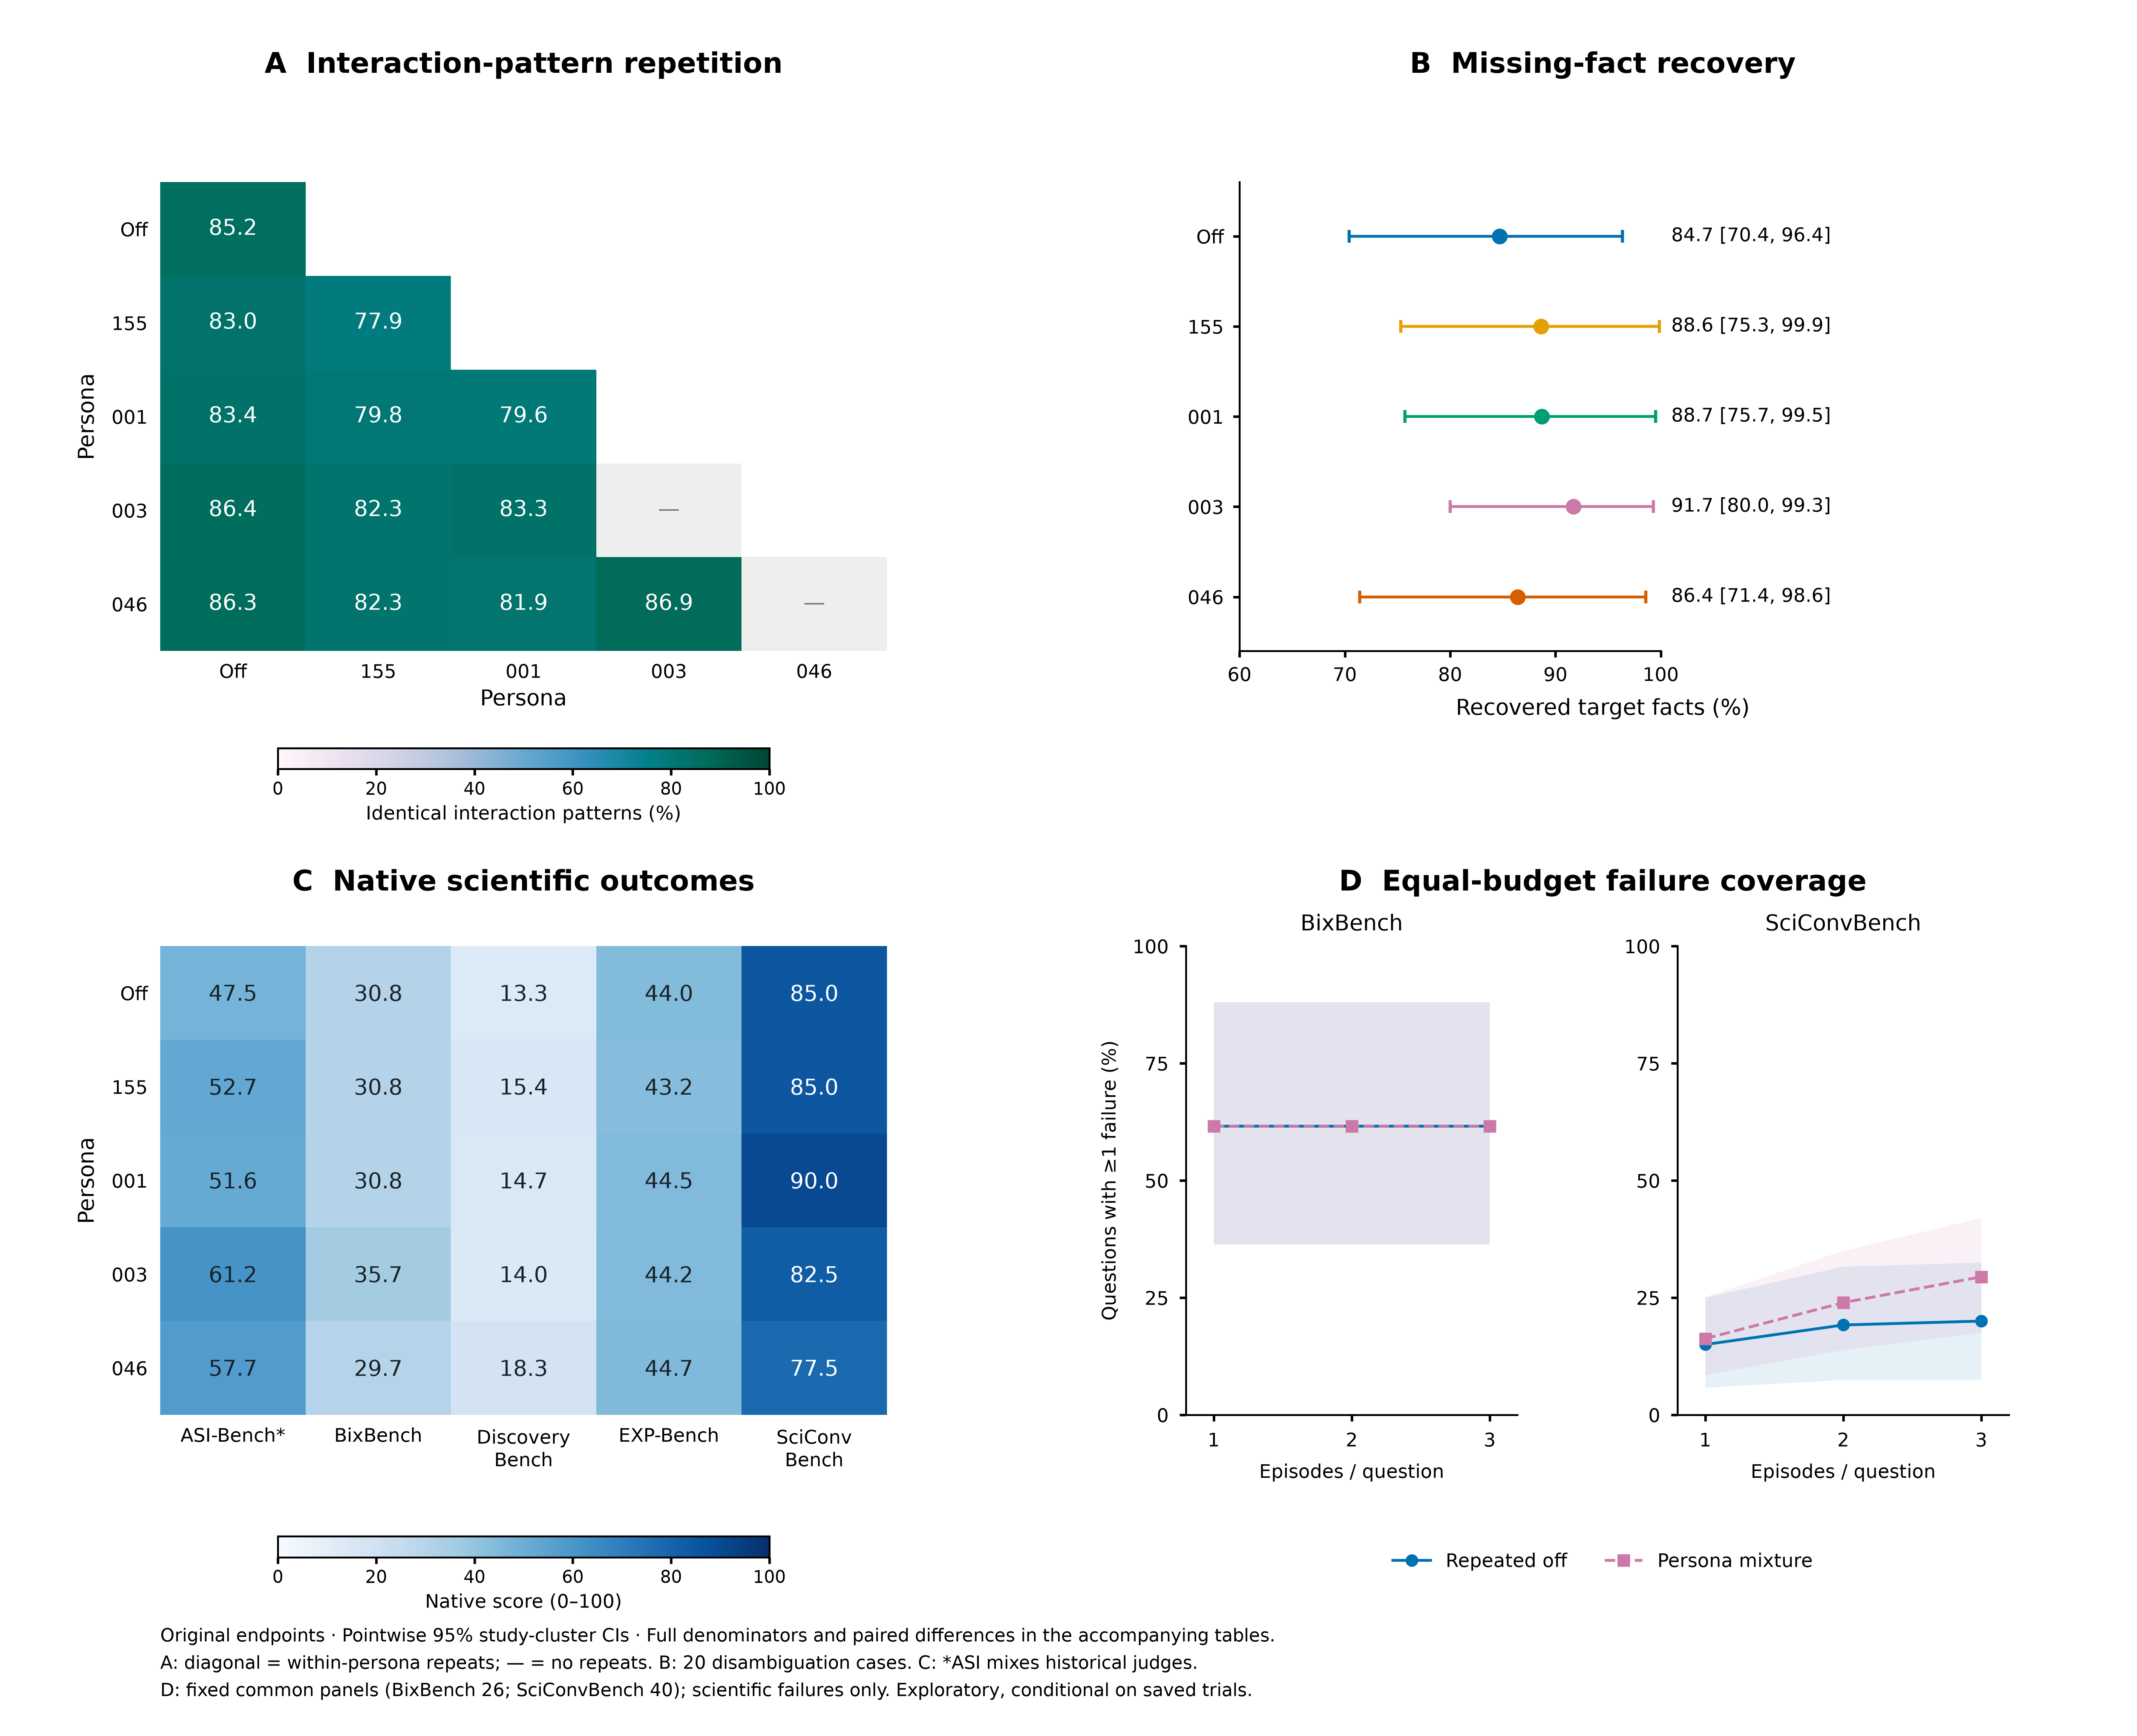

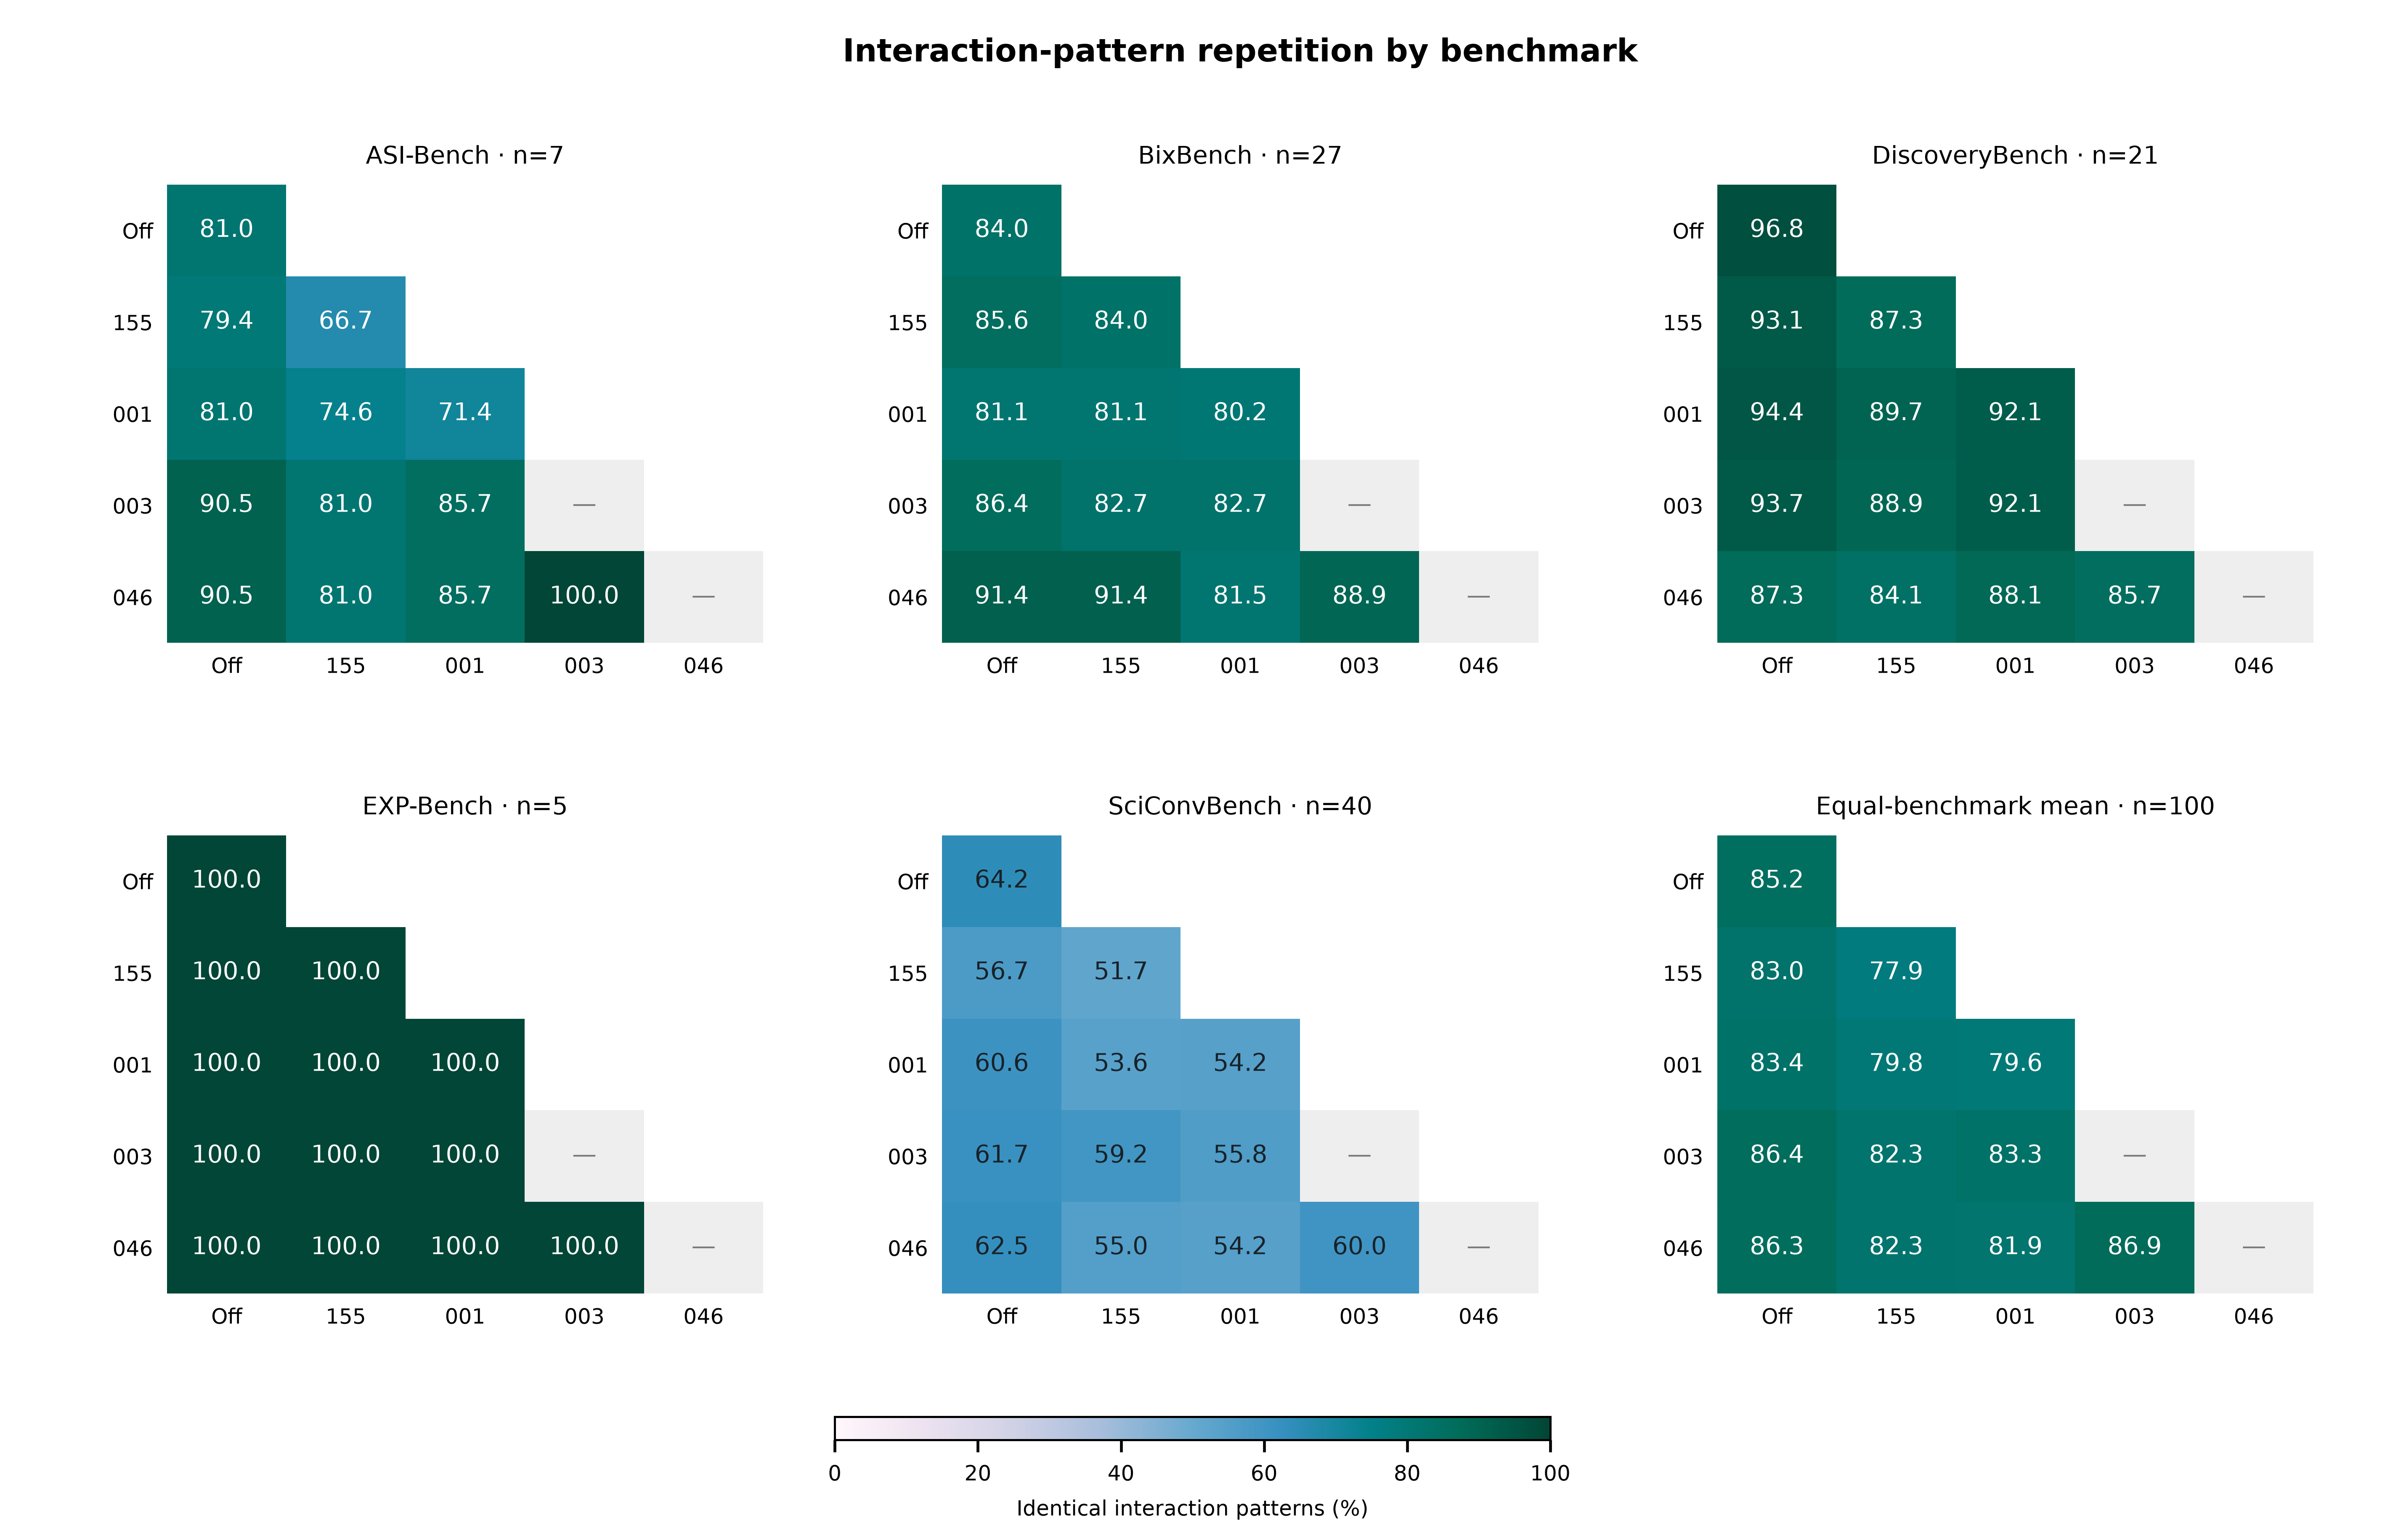

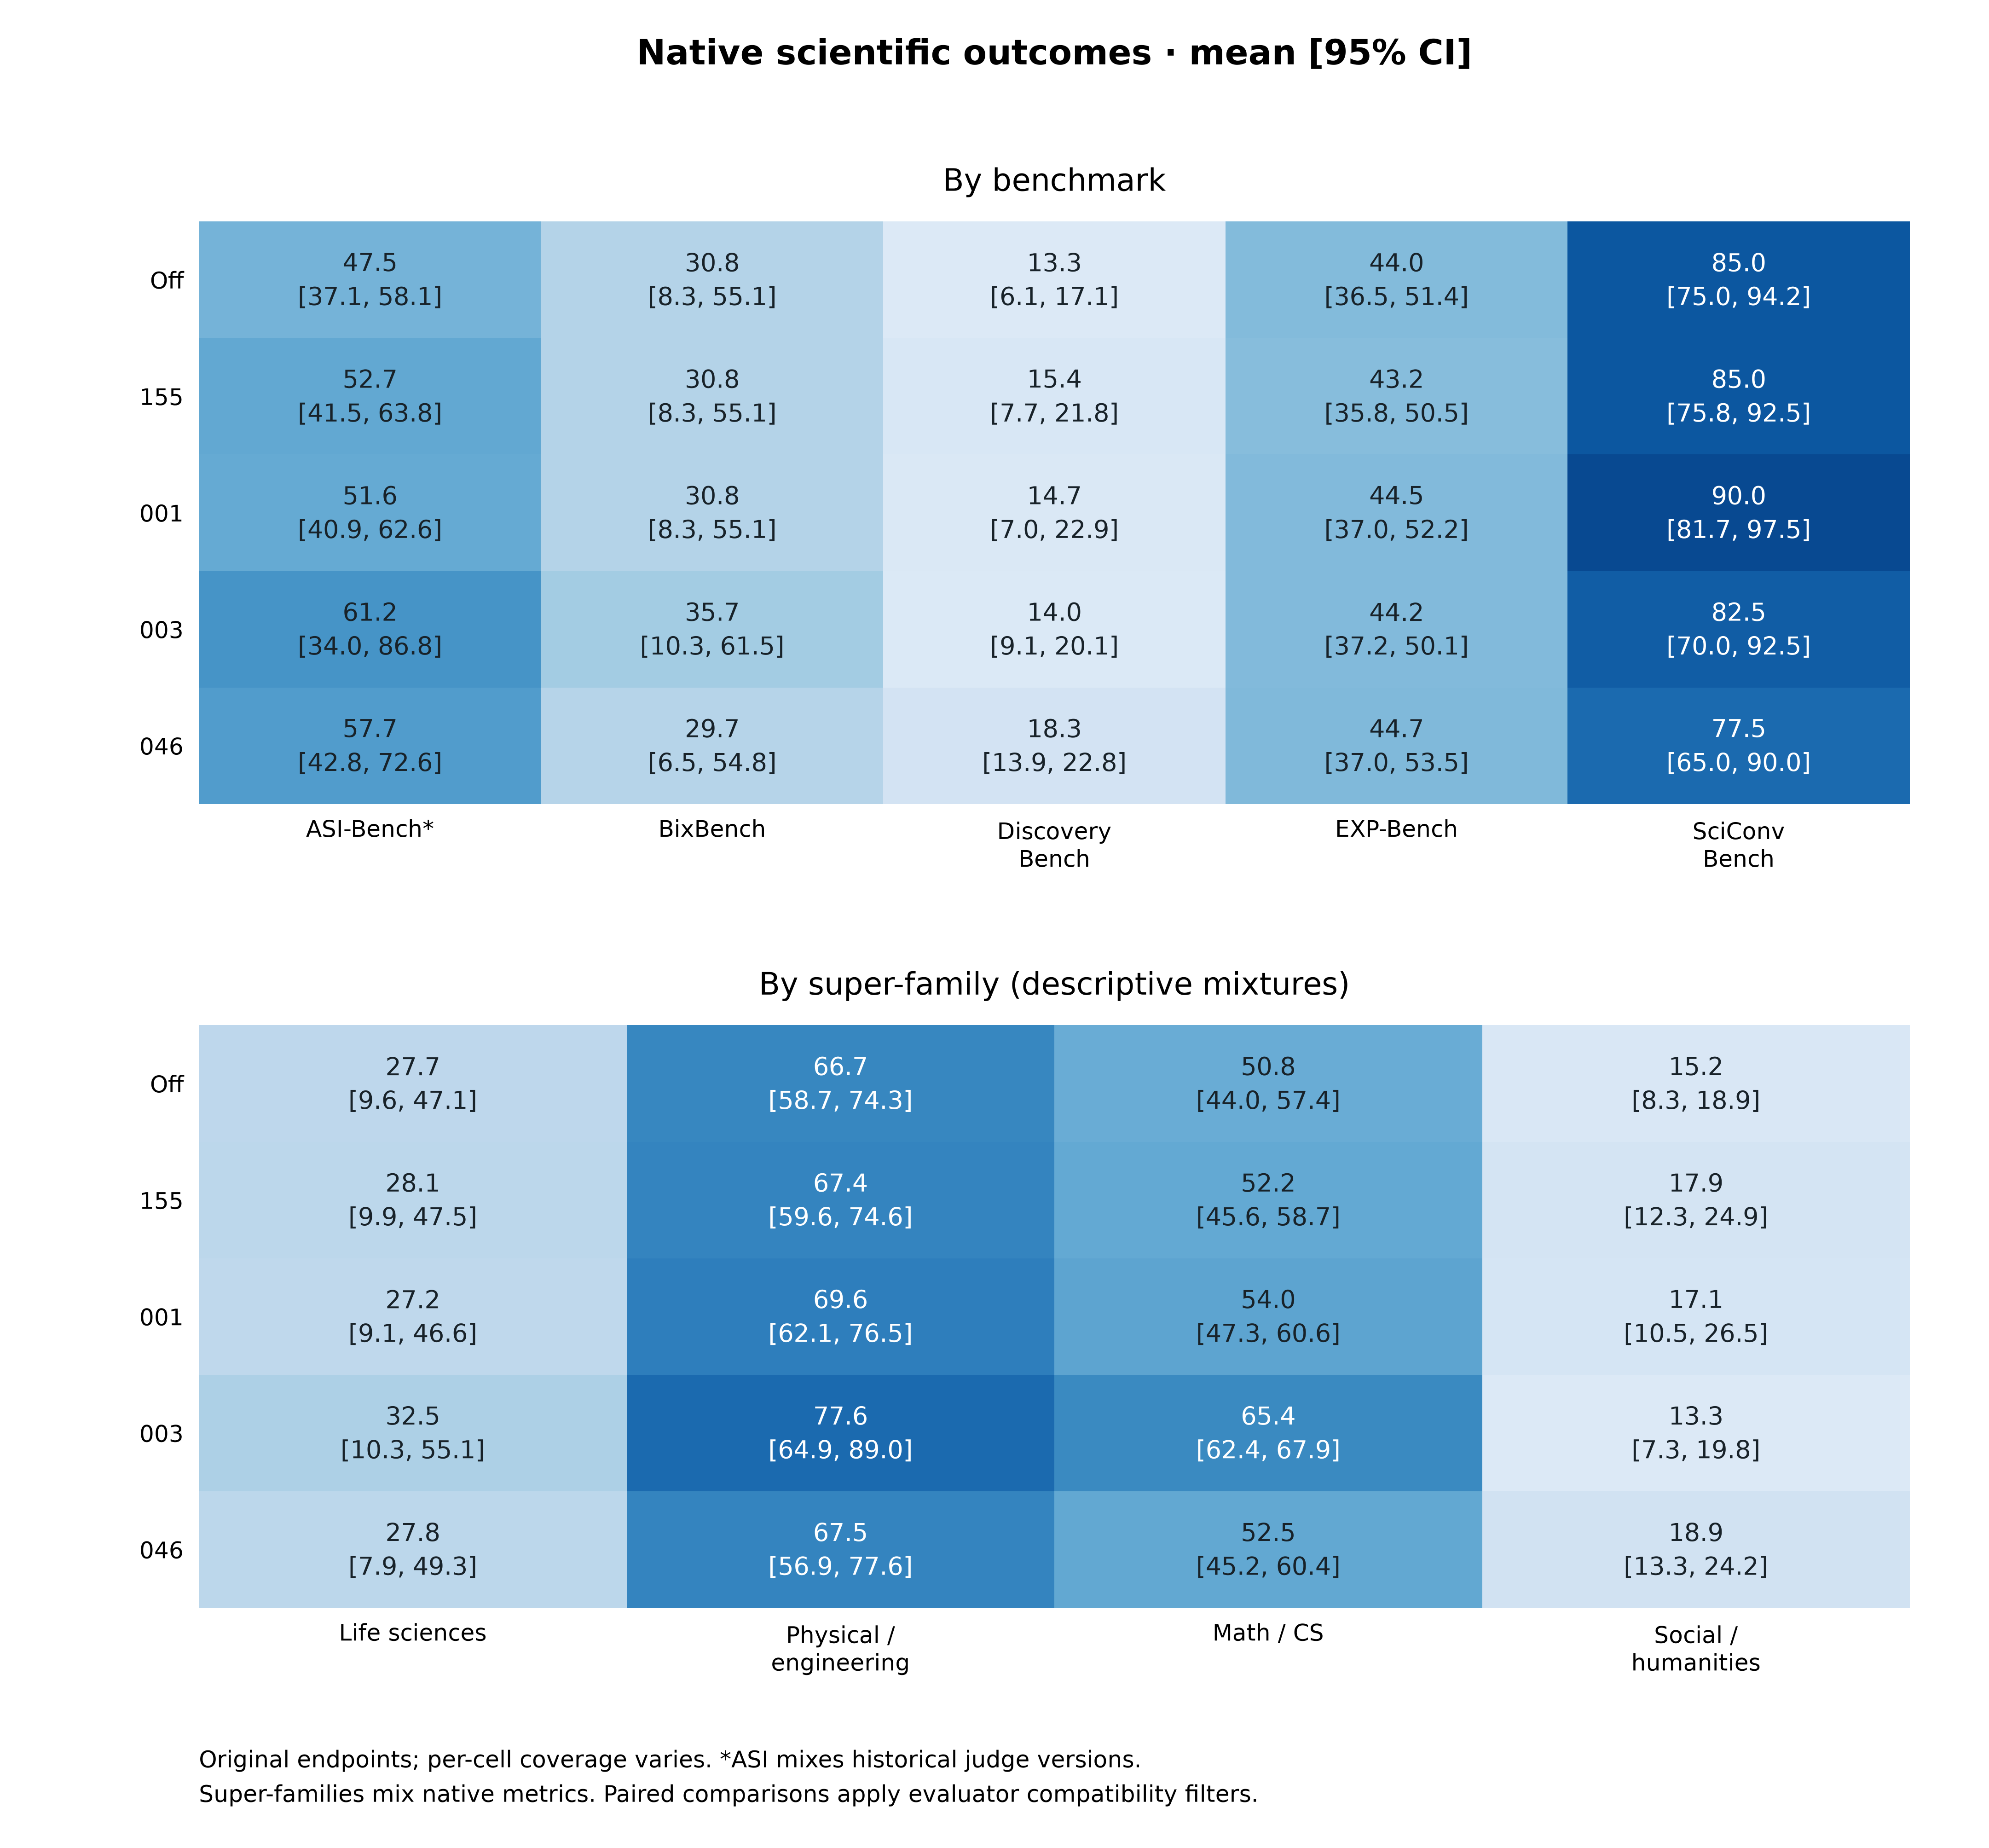

In [4]:
display(Code(Path(plot.__file__).read_text(),language='python'))
plot.main()
for name in ['metric_suite','repetition_by_benchmark','native_scores_with_ci']:
    display(Image(filename=str(plot.FIG/(name+'.png')),width=1250))

## Sensitivities and interpretation
Same-length structural comparisons remove exchange-count differences but change eligible pair coverage. SciConv’s same-length patterns are identical by protocol construction; do not interpret its lower raw repetition as semantic strategy diversity. Intent-preserved failure coverage conditions on native intent flags, is secondary and does not prove full factual fidelity. Earlier recovery CIs used domain stratification; this integrated suite uses source-study clusters, so intervals can differ although means reproduce. Native absolute ASI scores mix historical evaluators; paired comparisons enforce corrected judges. Full methods and cell denominators are in REPORT.md.

In [5]:
checks=subprocess.run([sys.executable,str(BASE/'code/test_metrics.py')],capture_output=True,text=True,check=True)
print(checks.stdout+checks.stderr)
print('Same-length SciConv matched pattern rates:',sorted({round(r['mean'],8) for r in s['repetition'] if r['variant']=='same_length' and r['level']=='source' and r['group']=='sciconvbench' and r['mean'] is not None}))
display(Markdown((BASE/'FIGURE_CAPTION.md').read_text()))

......
----------------------------------------------------------------------
Ran 6 tests in 0.058s

OK

Same-length SciConv matched pattern rates: [100.0]


# Candidate manuscript caption

**Interaction structure, information recovery and scientific evaluation coverage under five simulator settings.** Off, 155, 001, 003 and 046 use saved original Astra-low episodes; off/155/001 have three trials and 003/046 one. **A**, probability that two episodes for the same question have identical canonical native-event sequences. Off-diagonal cells compare personas; diagonal cells compare distinct repeats, with unavailable single-trial diagonals marked by a dash. Questions average within benchmark, then five benchmarks receive equal weight. The common panel contains 100 questions (ASI 7, Bix 27, Discovery 21, EXP 5, SciConv 40). This measures structural repetition, not semantic similarity. **B**, mean recovered missing-fact fraction on 20 SciConv disambiguation cases, with pointwise 95% confidence intervals. **C**, available native scientific scores; ASI absolute values mix historical judges. **D**, expected failed-task coverage under repeated-off versus a uniform mixture of distinct personas at one to three episodes per question, on fixed compatible panels of 26 Bix and 40 SciConv questions. Bands show pointwise 95% confidence intervals. All intervals resample source-study clusters 20,000 times and condition on observed trials. Full cell intervals, matched contrasts, source data, exclusions and methods accompany the figure. Different panels have different eligible populations. Results are exploratory; diversity, human realism, scientific quality and failure-discovery utility are not interchangeable claims.

## Agent handoff

See REPORT.md and PLAN.md for estimator details, original endpoint policy, equal-budget allocation, same-length and intent-preserved sensitivities, known SciConv cap limitation and no-inference constraint. Code is in code/, numeric sources in data/, and main/supporting exports in figures/. Main point estimates must not be described as significant or causal. In SciConv, same-length native-event patterns match perfectly, so its structural signal is dialogue length/stopping. Paired fact-recovery deltas for single-trial personas use off trial 1 and need not equal differences from the three-trial absolute off mean. No raw private transcript text is published.
